# 1_1 Reading, concatenating and checking atlas .h5ad files

A worked example: load a few samples, join them, and run the checks worth running before
trusting the result.

Every file in the atlas has the same structure - CSR matrix, `obsm['spatial']`, and a
`uns['hsa']` block of 86 metadata fields - so loading is uniform. **Joining is not**, because
samples do not share a gene space, and that is where the useful part of this notebook is.

In [1]:
import os
import numpy as np, pandas as pd, anndata as ad, scanpy as sc
import matplotlib as mpl, matplotlib.pyplot as plt
from pathlib import Path

HSA = Path(os.environ.get("HSA_ROOT", "/data/yzy21/yy/space_agent/hsa"))  # override with HSA_ROOT to run elsewhere
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
INK, INK2 = "#0b0b0b", "#52514e"
mpl.rcParams.update({"figure.dpi": 130, "font.size": 9.5, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlelocation": "left",
                     "figure.facecolor": "white", "axes.facecolor": "white"})

## Find samples using the manifest

In [2]:
man = pd.read_csv(HSA / "runs/sample_manifest.csv", low_memory=False)
led = pd.read_csv(HSA / "runs/materialise_ledger.csv")
ok = led[led.status.astype(str).str.startswith("ok")]
cat = man.merge(ok[["source", "accession", "sample_id", "path"]],
                on=["source", "accession", "sample_id"]).query("usable")
print(f"{len(cat):,} materialised samples")

vis = cat[cat.accession.eq("GSE282302")].head(3)          # Visium pancreas, one panel
xen = cat[cat.accession.eq("GSE277080")].head(1)          # Xenium pancreas, 377-plex
display(pd.concat([vis, xen])[["accession", "sample_id", "technology_resolved",
                               "n_cells", "n_genes", "tissue", "disease_state"]])

7,668 materialised samples


,accession,sample_id,technology_resolved,n_cells,n_genes,tissue,disease_state
1631,GSE282302,GSM8641108,Visium,3996.0,19144.0,pancreas,disease
1632,GSE282302,GSM8641025,Visium,2387.0,19144.0,pancreas,disease
1636,GSE282302,GSM8641062,Visium,3568.0,19144.0,pancreas,disease
3390,GSE277080,GSM8513808,Xenium,55490.0,1208.0,prostate_gland,disease


## Load one and look at what a file carries

In [3]:
a = ad.read_h5ad(vis.path.iloc[0])
print(a)
u = dict(a.uns["hsa"])
print(f"\nuns['hsa'] has {len(u)} fields")
display(pd.Series({k: u[k] for k in ["tissue", "disease_level3", "technology_resolved",
                                     "preservation", "inferred_sex", "n_cells", "n_genes",
                                     "is_integer", "coord_source", "hsa_schema"]}).to_frame("value"))

AnnData object with n_obs × n_vars = 3996 × 19144
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'hsa'
    obsm: 'spatial'
    layers: None (.X)

uns['hsa'] has 86 fields


,value
tissue,pancreas
disease_level3,pancreatic_ductal_adenocarcinoma
technology_resolved,Visium
preservation,FFPE
inferred_sex,male
n_cells,3996.0
n_genes,19144.0
is_integer,True
coord_source,visium
hsa_schema,2


## Check before you trust: is this counts?

`is_integer` is recorded per sample because 577 files in the atlas hold normalised or residual
values rather than counts, and they sit in the same depth range as raw ones - nothing
downstream notices on its own.

In [4]:
X = a.X
print(f"dtype {X.dtype} | min {X.min():.3f} | max {X.max():.0f}")
print(f"all integral: {np.allclose(X.data, np.round(X.data))}")
print(f"manifest says is_integer = {u.get('is_integer')}")

dtype int32 | min 0.000 | max 4650


all integral: True
manifest says is_integer = True


## Concatenate samples that share a panel

In [5]:
parts = []
for _, r in vis.iterrows():
    s = ad.read_h5ad(r.path)
    s.obs["sample_id"] = r.sample_id
    s.obs["accession"] = r.accession
    s.var_names_make_unique()
    parts.append(s)

joined = ad.concat(parts, join="inner", label="batch", keys=list(vis.sample_id),
                   index_unique="-")
print(f"{len(parts)} samples -> {joined.shape[0]:,} spots x {joined.shape[1]:,} genes")
print("genes per input:", [p.n_vars for p in parts])
print("after inner join:", joined.n_vars)

3 samples -> 9,951 spots x 19,144 genes
genes per input: [19144, 19144, 19144]
after inner join: 19144


## Quick QC across the joined samples

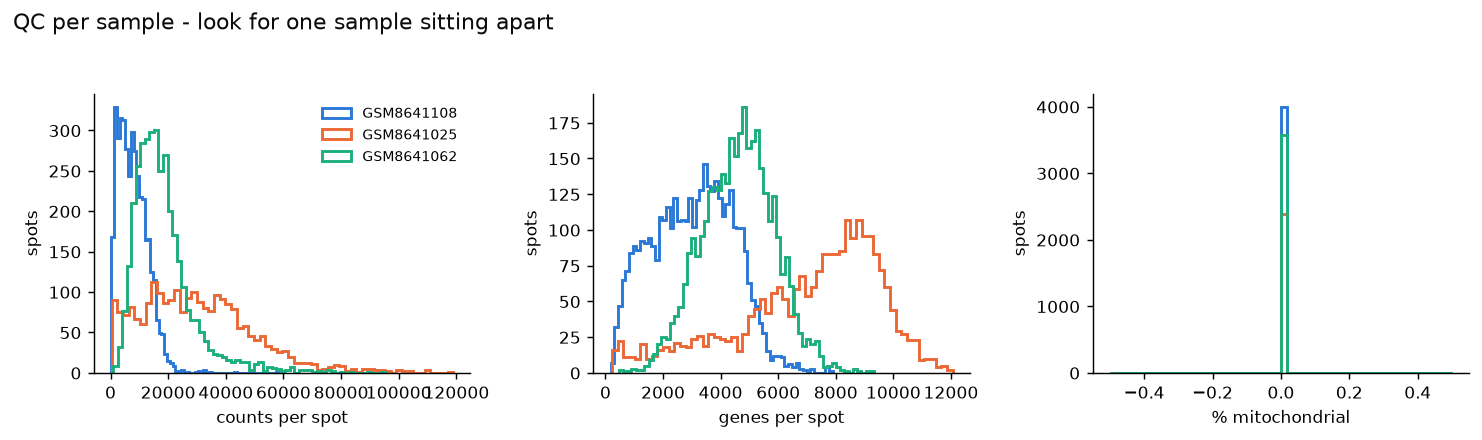

,total_counts,n_genes_by_counts,pct_counts_mt
sample_id,,,
GSM8641025,28121.0,7617.0,0.0
GSM8641062,16174.5,4651.5,0.0
GSM8641108,7180.5,3098.5,0.0


In [6]:
joined.var["mt"] = joined.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(joined, qc_vars=["mt"], inplace=True, percent_top=None, log1p=False)

fig, axes = plt.subplots(1, 3, figsize=(11.4, 3.4))
for ax, col, lab in [(axes[0], "total_counts", "counts per spot"),
                     (axes[1], "n_genes_by_counts", "genes per spot"),
                     (axes[2], "pct_counts_mt", "% mitochondrial")]:
    for i, s in enumerate(joined.obs.sample_id.unique()):
        v = joined.obs.loc[joined.obs.sample_id.eq(s), col]
        ax.hist(v, bins=60, histtype="step", lw=1.6, color=C[i], label=s)
    ax.set_xlabel(lab); ax.set_ylabel("spots")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("QC per sample - look for one sample sitting apart", x=.005, ha="left",
             fontsize=12, color=INK)
fig.tight_layout(rect=[0, 0, 1, .93]); plt.show()
display(joined.obs.groupby("sample_id")[["total_counts", "n_genes_by_counts", "pct_counts_mt"]]
        .median().round(1))

## Where the spots actually are

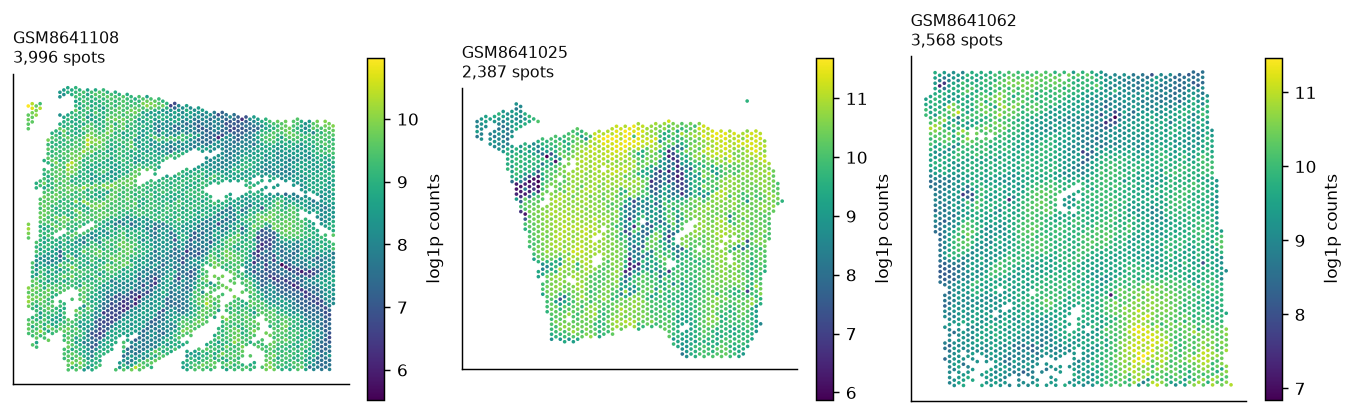

In [7]:
n = len(parts)
fig, axes = plt.subplots(1, n, figsize=(3.5 * n, 3.4))
for ax, p, sid in zip(np.atleast_1d(axes), parts, vis.sample_id):
    xy = p.obsm["spatial"]
    tot = np.asarray(p.X.sum(1)).ravel()
    sm = ax.scatter(xy[:, 0], -xy[:, 1], c=np.log1p(tot), s=4, cmap="viridis", lw=0)
    ax.set_title(f"{sid}\n{p.n_obs:,} spots", fontsize=9, color=INK)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect("equal")
    plt.colorbar(sm, ax=ax, fraction=.046, label="log1p counts")
fig.tight_layout(); plt.show()

## The part that goes wrong: joining across platforms

A Visium sample carries 19,144 genes; a Xenium panel carries 377. `join="outer"` fills the
missing genes with **zero**, so a gene that Xenium never measured becomes a gene Xenium measured
as absent. Downstream, that is indistinguishable from a real zero.

In [8]:
x = ad.read_h5ad(xen.path.iloc[0]); x.var_names_make_unique()
x.obs["sample_id"] = xen.sample_id.iloc[0]
v = parts[0]
shared = set(v.var_names) & set(x.var_names)
print(f"Visium {v.n_vars:,} genes | Xenium {x.n_vars:,} genes | shared {len(shared):,}")

outer = ad.concat([v, x], join="outer", label="platform",
                  keys=["Visium", "Xenium"], index_unique="-")
inner = ad.concat([v, x], join="inner", label="platform",
                  keys=["Visium", "Xenium"], index_unique="-")
print(f"\nouter join: {outer.shape}   <- Xenium cells gain {outer.n_vars - x.n_vars:,} fake zeros each")
print(f"inner join: {inner.shape}   <- only genes both platforms measured")

Visium 19,144 genes | Xenium 1,207 genes | shared 959



outer join: (59486, 19392)   <- Xenium cells gain 18,185 fake zeros each
inner join: (59486, 959)   <- only genes both platforms measured


In [9]:
# what that does to a gene Xenium never measured
probe = [g for g in v.var_names if g not in shared][:1]
if probe:
    g = probe[0]
    sub = outer[:, g]
    byp = pd.DataFrame({"platform": outer.obs.platform.values,
                        "expr": np.asarray(sub.X.todense()).ravel()})
    tab = byp.groupby("platform").expr.agg(mean="mean", frac_zero=lambda s: (s == 0).mean())
    print(f"gene {g!r} is in the Visium panel only\n")
    display(tab.round(4))
    print("Xenium shows 100% zero - but it was never measured, not measured-and-absent.")

gene 'OR4F5' is in the Visium panel only



,mean,frac_zero
platform,,
Visium,0.0035,0.9965
Xenium,0.0000,1.0000


Xenium shows 100% zero - but it was never measured, not measured-and-absent.


## The honest join

Use `join="inner"`, and record what was dropped. If genes outside the shared set matter, the
samples do not belong in one matrix - compare them per platform instead.

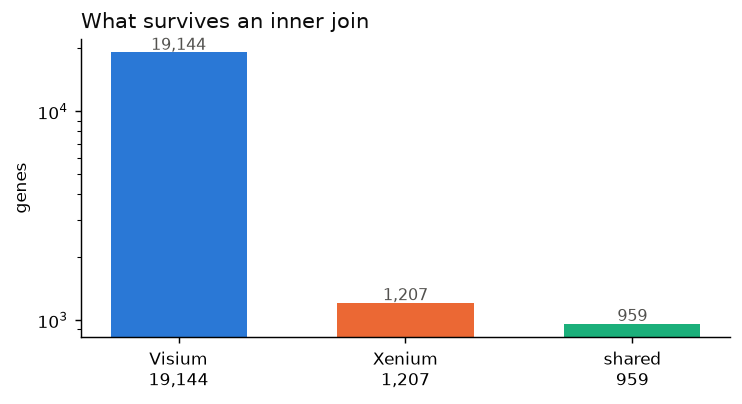

inner join keeps 5.0% of the Visium panel and 79.5% of the Xenium panel


In [10]:
fig, ax = plt.subplots(figsize=(5.8, 3.2))
sizes = [v.n_vars, x.n_vars, len(shared)]
labs = [f"Visium\n{v.n_vars:,}", f"Xenium\n{x.n_vars:,}", f"shared\n{len(shared):,}"]
ax.bar(range(3), sizes, color=[C[0], C[1], C[2]], width=.6)
for i, s in enumerate(sizes):
    ax.text(i, s * 1.03, f"{s:,}", ha="center", fontsize=9, color=INK2)
ax.set_xticks(range(3)); ax.set_xticklabels(labs); ax.set_yscale("log")
ax.set_ylabel("genes"); ax.set_title("What survives an inner join", color=INK)
fig.tight_layout(); plt.show()
print(f"inner join keeps {len(shared)/v.n_vars*100:.1f}% of the Visium panel "
      f"and {len(shared)/x.n_vars*100:.1f}% of the Xenium panel")